# Double descent — book graphics 6: bias–variance (parabolic fits)

Still versions of the bias–variance section of `p65_68_rewrite.py`.

Datasets are drawn exactly as in the video / `Final Video Polynomial Examples.ipynb`: `get_noisy_data(random_seed=i)` for i = 0, 1, 2, …, 10 points each, first 5 used for training, degree-2 Legendre pseudoinverse fit. (The video's `variance_fits_oct_14_1.npy` is seeds 0–49.)

Exports:

- **`grid_fits.svg`** — `GRID_ROWS × GRID_COLS` small multiples: one dataset + its parabolic fit per cell, over the underlying function.
- **`mean_std.svg`** — mean fit with a ±1 std shaded band, on top of the underlying function.
- **`mean_std_bias.svg`** — same, plus the region between the mean fit and the underlying function shaded (the bias).
- **`all_fits.svg`** — all `N_FITS` thin fits overlaid (optional companion).
- each of the large panels also as `*_unclipped` (y-range widened at the same inches-per-unit).


## 1. Config

In [1]:
from pathlib import Path
import numpy as np
import scipy.special
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# ── Book palette ───────────────────────────────────────────────────────────
CHILL_BROWN = '#948979'
LT_BLUE     = '#5badb6'
ORANGE      = '#eb8423'
GREEN       = '#419c52'
BLUE        = '#236c94'
RED         = '#d73b2f'
PINK        = '#ed5e78'
YELLOW      = '#fcc947'
LT_PURPLE   = '#b2c2e4'
PURPLE      = '#7e5b76'

AXIS_COLOR   = CHILL_BROWN
CURVE_COLOR  = CHILL_BROWN           # underlying function f(x)
TRAIN_COLOR  = LT_BLUE
TEST_COLOR   = ORANGE
FIT_COLOR    = BLUE                  # degree-2 fits (same as the 2nd-order fit in graphics 1)
MEAN_COLOR   = BLUE                  # mean fit
STD_COLOR    = BLUE                  # ±1 std band
STD_ALPHA    = 0.4
BIAS_COLOR   = PINK                  # region between mean fit and f(x)
BIAS_ALPHA   = 0.8

# ── Data / fits (matches the video) ────────────────────────────────────────
N_POINTS    = 10
NOISE_LEVEL = 0.2
TRAIN_FRAC  = 0.5
X_MIN, X_MAX = -2.0, 2.0
def f(x): return 0.5 * x**2
DEGREE      = 2
N_FITS      = 24 #50                     # datasets (seeds 0..N_FITS-1) used for the mean / std / bias panels

# ── Grid of small multiples ────────────────────────────────────────────────
GRID_ROWS, GRID_COLS = 4, 6
GRID_SEEDS  = list(range(GRID_ROWS * GRID_COLS))   # which datasets go in the grid (row-major)
GRID_CELL_IN  = (1.4, 1.2)           # axes box size per cell, inches
GRID_GAP_IN   = (0.25, 0.25)         # horizontal / vertical gap between cells
GRID_SHOW_TEST   = False              # draw the 5 test points in each cell too
GRID_DOT_SIZE    = 10
GRID_LINEWIDTH   = 1.2               # fit line in each cell
GRID_CURVE_LW    = 1.0               # underlying function in each cell
GRID_TICK_LABELS = 'edges'           # 'edges' = left column + bottom row only, 'all', or 'none'
GRID_FONTSIZE    = 7
GRID_SHOW_SEED   = False             # tiny seed label in each cell (handy while choosing which to keep)

# ── Large panel ────────────────────────────────────────────────────────────
AX_WIDTH_IN     = 4.0
AX_HEIGHT_IN    = 3.4                # for the clipped y-range YLIM
MARGIN_IN       = 0.6
LINEWIDTH       = 2.0                # underlying curve + mean fit
ALL_FITS_LINEWIDTH = 0.6
ALL_FITS_ALPHA     = 0.4
AXIS_LINEWIDTH  = 1.0
FONTSIZE        = 10
XLIM            = (X_MIN, X_MAX)
YLIM            = (-0.5, 2.0)
UNCLIP_YLIM     = None               # None = widen to contain the ±std band / all fits (+UNCLIP_PAD)
UNCLIP_PAD      = 0.25
X_TICK_STEP     = 1.0
Y_TICK_STEP     = 1.0
SPINES          = 'lb'
SHOW_TICKS      = True
CURVE_ALPHA     = 0.5
CURVE_LINESTYLE = '-'
SHOW_MEAN_LINE  = True
TRANSPARENT     = True

# ── Fonts: LaTeX / Computer Modern look ────────────────────────────────────
USE_TEX = True
plt.rcParams['font.family']  = 'serif'
plt.rcParams['font.serif']   = ['cmr10', 'Computer Modern Roman', 'DejaVu Serif']
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['axes.formatter.use_mathtext'] = True
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['text.usetex']  = USE_TEX
plt.rcParams['svg.fonttype'] = 'none'

# ── Output ─────────────────────────────────────────────────────────────────
OUT_DIR = Path('/Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/5_double_descent/graphics/bias_variance')
SAVE    = True
OUT_DIR.mkdir(parents=True, exist_ok=True)


## 2. Fit helpers

In [2]:
def legendre_features(x, degree, x_min=X_MIN, x_max=X_MAX):
    x_scaled = 2 * (x - x_min) / (x_max - x_min) - 1
    return scipy.special.eval_legendre(np.arange(degree + 1)[:, None], x_scaled).T

def fit_legendre_pinv(x_train, y_train, degree):
    return np.linalg.pinv(legendre_features(x_train, degree)) @ y_train

def eval_legendre_poly(beta, x, degree):
    return legendre_features(x, degree) @ beta

def get_noisy_data(n_points=N_POINTS, noise_level=NOISE_LEVEL, random_seed=0):
    np.random.seed(random_seed)
    x = np.random.uniform(X_MIN, X_MAX, n_points)
    y = f(x) + noise_level * np.random.randn(n_points)
    return x, y


## 3. Datasets + fits

In [3]:
all_x = np.linspace(X_MIN, X_MAX, 128)
all_y = f(all_x)
n_train = int(np.floor(N_POINTS * TRAIN_FRAC))

def dataset(seed):
    """One dataset + its degree-DEGREE fit."""
    x, y = get_noisy_data(random_seed=seed)
    x_train, y_train = x[:n_train], y[:n_train]
    x_test,  y_test  = x[n_train:], y[n_train:]
    beta = fit_legendre_pinv(x_train, y_train, DEGREE)
    return dict(seed=seed, x_train=x_train, y_train=y_train, x_test=x_test, y_test=y_test,
                beta=beta, curve=eval_legendre_poly(beta, all_x, DEGREE))

seeds_needed = sorted(set(range(N_FITS)) | set(GRID_SEEDS))
data = {s: dataset(s) for s in seeds_needed}

fits     = np.array([data[s]['curve'] for s in range(N_FITS)])   # (N_FITS, 128)
mean_fit = fits.mean(0)
std_fit  = fits.std(0)
bias_sq  = np.mean((all_y - mean_fit)**2)          # mean over x of (f - mean fit)^2
variance = np.mean((fits - mean_fit)**2)           # mean over x and datasets of (fit - mean fit)^2

print(f'{N_FITS} degree-{DEGREE} fits: curve range {fits.min():.2f} .. {fits.max():.2f}')
print(f'mean fit range {mean_fit.min():.2f} .. {mean_fit.max():.2f};  ±1 std band range '
      f'{(mean_fit - std_fit).min():.2f} .. {(mean_fit + std_fit).max():.2f}')
print(f'bias^2 = {bias_sq:.4f}   variance = {variance:.4f}')


24 degree-2 fits: curve range -0.24 .. 4.00
mean fit range 0.02 .. 2.10;  ±1 std band range -0.09 .. 2.68
bias^2 = 0.0019   variance = 0.0891


## 4. Renderers

In [4]:
X_IN_PER_UNIT = AX_WIDTH_IN  / (XLIM[1] - XLIM[0])
Y_IN_PER_UNIT = AX_HEIGHT_IN / (YLIM[1] - YLIM[0])

def exact_axes(width_in, height_in, margin=MARGIN_IN):
    fig = plt.figure(figsize=(width_in + 2 * margin, height_in + 2 * margin))
    ax = fig.add_axes([margin / fig.get_figwidth(), margin / fig.get_figheight(),
                       width_in / fig.get_figwidth(), height_in / fig.get_figheight()])
    return fig, ax

def style_ax(ax, color=AXIS_COLOR, fontsize=FONTSIZE, show_ticks=SHOW_TICKS):
    if SPINES == 'lb':
        ax.spines[['top', 'right']].set_visible(False)
    ax.spines[:].set_color(color)
    ax.spines[:].set_linewidth(AXIS_LINEWIDTH)
    ax.tick_params(colors=color, labelsize=fontsize, width=AXIS_LINEWIDTH, which='both')
    if not show_ticks:
        ax.set_xticks([]); ax.set_yticks([])

# ── grid of small multiples ────────────────────────────────────────────────
def draw_cell(ax, d, show_xlabels, show_ylabels):
    ax.plot(all_x, all_y, color=CURVE_COLOR, lw=GRID_CURVE_LW, ls=CURVE_LINESTYLE, alpha=CURVE_ALPHA, zorder=1)
    ax.plot(all_x, d['curve'], color=FIT_COLOR, lw=GRID_LINEWIDTH, zorder=3, solid_capstyle='round')
    ax.scatter(d['x_train'], d['y_train'], s=GRID_DOT_SIZE, color=TRAIN_COLOR, zorder=4, linewidths=0)
    if GRID_SHOW_TEST:
        ax.scatter(d['x_test'], d['y_test'], s=GRID_DOT_SIZE, color=TEST_COLOR, zorder=4, linewidths=0)
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM)
    ax.xaxis.set_major_locator(MultipleLocator(X_TICK_STEP))
    ax.yaxis.set_major_locator(MultipleLocator(Y_TICK_STEP))
    style_ax(ax, fontsize=GRID_FONTSIZE)
    ax.tick_params(labelbottom=show_xlabels, labelleft=show_ylabels)
    if GRID_SHOW_SEED:
        ax.text(0.04, 0.92, str(d['seed']), transform=ax.transAxes, fontsize=GRID_FONTSIZE, color=AXIS_COLOR, va='top')

def grid_figure():
    cw, ch = GRID_CELL_IN; gx, gy = GRID_GAP_IN
    W = 2 * MARGIN_IN + GRID_COLS * cw + (GRID_COLS - 1) * gx
    H = 2 * MARGIN_IN + GRID_ROWS * ch + (GRID_ROWS - 1) * gy
    fig = plt.figure(figsize=(W, H))
    axes = []
    for r in range(GRID_ROWS):
        for c in range(GRID_COLS):
            k = r * GRID_COLS + c
            if k >= len(GRID_SEEDS):
                break
            x0 = MARGIN_IN + c * (cw + gx)
            y0 = H - MARGIN_IN - ch - r * (ch + gy)
            ax = fig.add_axes([x0 / W, y0 / H, cw / W, ch / H])
            if GRID_TICK_LABELS == 'all':
                show_x = show_y = True
            elif GRID_TICK_LABELS == 'edges':
                show_x, show_y = (r == GRID_ROWS - 1), (c == 0)
            else:
                show_x = show_y = False
            draw_cell(ax, data[GRID_SEEDS[k]], show_x, show_y)
            axes.append(ax)
    return fig, axes

# ── large panels ───────────────────────────────────────────────────────────
def panel_ylim(clip, kind):
    if clip:
        return YLIM
    if UNCLIP_YLIM is not None:
        return UNCLIP_YLIM
    if kind == 'all_fits':
        lo, hi = fits.min(), fits.max()
    else:
        lo, hi = (mean_fit - std_fit).min(), (mean_fit + std_fit).max()
    return (min(YLIM[0], lo - UNCLIP_PAD), max(YLIM[1], hi + UNCLIP_PAD))

def draw_panel(ax, kind='mean_std', clip=True):
    """kind: 'mean_std' | 'mean_std_bias' | 'all_fits'"""
    ylim = panel_ylim(clip, kind)
    ax.plot(all_x, all_y, color=CURVE_COLOR, lw=LINEWIDTH, ls=CURVE_LINESTYLE, alpha=CURVE_ALPHA,
            zorder=3, solid_capstyle='round')
    if kind == 'all_fits':
        for c in fits:
            ax.plot(all_x, c, color=FIT_COLOR, lw=ALL_FITS_LINEWIDTH, alpha=ALL_FITS_ALPHA, zorder=2)
    else:
        ax.fill_between(all_x, mean_fit - std_fit, mean_fit + std_fit, color=STD_COLOR, alpha=STD_ALPHA,
                        lw=0, zorder=1)
        if kind == 'mean_std_bias':
            ax.fill_between(all_x, mean_fit, all_y, color=BIAS_COLOR, alpha=BIAS_ALPHA, lw=0, zorder=2)
        if SHOW_MEAN_LINE:
            ax.plot(all_x, mean_fit, color=MEAN_COLOR, lw=LINEWIDTH, zorder=4, solid_capstyle='round')
    ax.set_xlim(*XLIM); ax.set_ylim(*ylim)
    ax.xaxis.set_major_locator(MultipleLocator(X_TICK_STEP))
    ax.yaxis.set_major_locator(MultipleLocator(Y_TICK_STEP))
    style_ax(ax)

def panel_figure(kind='mean_std', clip=True):
    ylim = panel_ylim(clip, kind)
    fig, ax = exact_axes(AX_WIDTH_IN, (ylim[1] - ylim[0]) * Y_IN_PER_UNIT)
    draw_panel(ax, kind, clip)
    return fig, ax


## 5. Preview

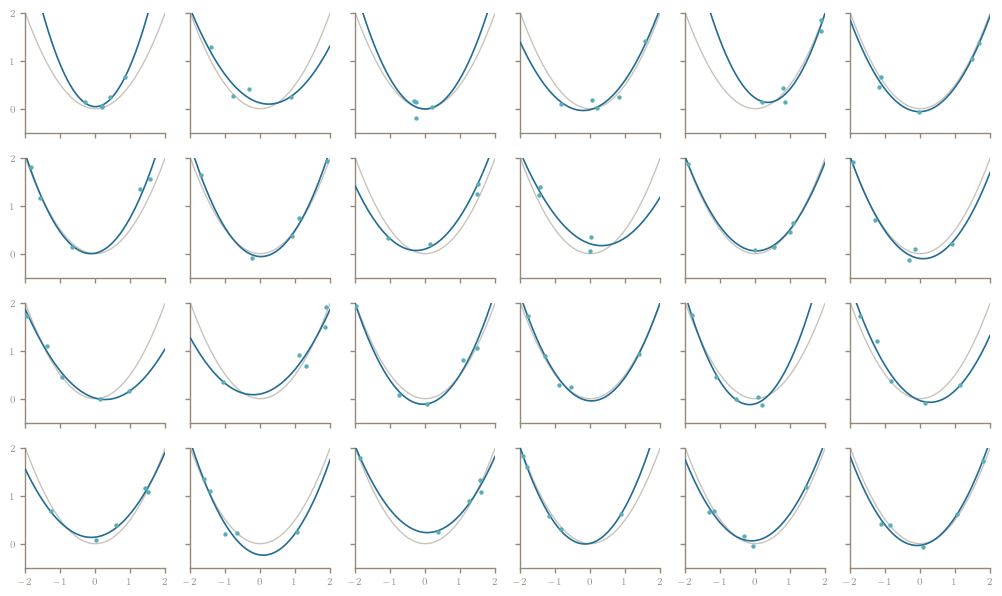

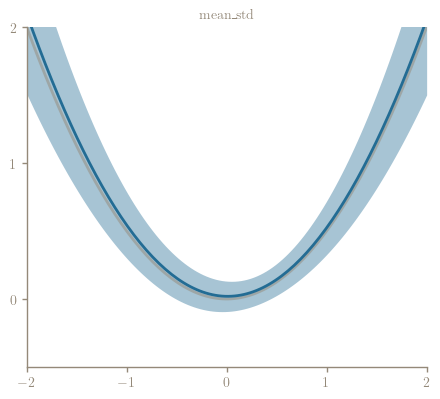

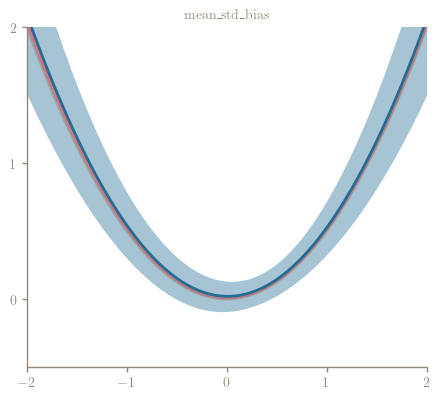

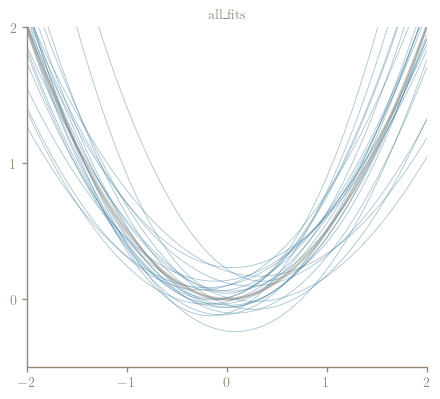

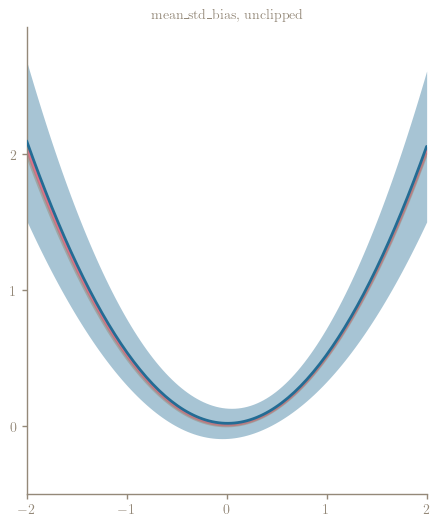

In [5]:
fig, _ = grid_figure(); plt.show()
for kind in ('mean_std', 'mean_std_bias', 'all_fits'):
    fig, ax = panel_figure(kind, clip=True)
    ax.set_title(kind, color=AXIS_COLOR, fontsize=FONTSIZE); plt.show()
fig, ax = panel_figure('mean_std_bias', clip=False)
ax.set_title('mean_std_bias, unclipped', color=AXIS_COLOR, fontsize=FONTSIZE); plt.show()


## 6. Export

In [6]:
def save(fig, stem):
    for ext in ('svg', 'png'):
        fig.savefig(OUT_DIR / f'{stem}.{ext}', dpi=300, transparent=TRANSPARENT, bbox_inches='tight')
    plt.close(fig)

if SAVE:
    fig, _ = grid_figure(); save(fig, f'grid_fits_{GRID_ROWS}x{GRID_COLS}')
    for kind in ('mean_std', 'mean_std_bias', 'all_fits'):
        for clip in (True, False):
            fig, _ = panel_figure(kind, clip)
            save(fig, kind + ('' if clip else '_unclipped'))
    print('saved to', OUT_DIR)
    for p in sorted(OUT_DIR.glob('*.svg')):
        print('  ', p.name)


saved to /Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/5_double_descent/graphics/bias_variance
   all_fits.svg
   all_fits_unclipped.svg
   grid_fits_4x6.svg
   mean_std.svg
   mean_std_bias.svg
   mean_std_bias_unclipped.svg
   mean_std_unclipped.svg
